# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [ ]:
# Варіант 1. Завантаження файлу в Google Colab
import pandas as pd
from google.colab import files
files.upload()
df = pd.read_csv('data.csv')
df.head()

Saving data.csv to data.csv


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


In [ ]:
# Варіант 2. Завантаження датасету через KaggleHub
# import kagglehub
# import os
# path = kagglehub.dataset_download('unmoved/cure-the-princess')
# df = pd.read_csv(os.path.join(path, 'data.csv'))
# df.head()

### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [ ]:
# TODO: виведіть перші рядки, структуру й розмір датасету
# Підказка: head(), info(), shape
display(df.head())
df.info()
print("\nРозмір датасету (рядки, стовпці):", df.shape)

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB

Розмір датасету (рядки, стовпці): (2338, 14)


In [ ]:
# TODO: перевірте кількість пропусків і дублікатів
# Підказка: isnull().sum(), duplicated().sum()
print("Кількість пропусків у кожному стовпці:")
print(df.isnull().sum())
print("\nЗагальна кількість дублікатів:", df.duplicated().sum())

Кількість пропусків у кожному стовпці:
Phoenix Feather    0
Unicorn Horn       0
Dragon's Blood     0
Mermaid Tears      0
Fairy Dust         0
Goblin Toes        0
Witch's Brew       0
Griffin Claw       0
Troll Hair         0
Kraken Ink         0
Minotaur Horn      0
Basilisk Scale     0
Chimera Fang       0
Cured              0
dtype: int64

Загальна кількість дублікатів: 0


In [ ]:
# TODO: виведіть описову статистику
# Підказка: describe()
display(df.describe())

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
count,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000
mean,15.365697,10.946749,16.115654,13.627973,15.069504,14.157271,12.328914,14.911206,16.871685,14.890590,10.916125,15.371600,12.084003,0.496578
std,8.669969,7.225162,8.372518,7.545244,8.349340,7.831476,7.709753,8.132678,9.579027,8.014197,7.045195,8.559139,8.047540,0.500095
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,8.500000,5.300000,9.600000,7.600000,8.625000,7.900000,6.325000,8.400000,8.900000,8.800000,5.200000,8.800000,5.600000,0.000000
50%,14.700000,9.500000,15.800000,13.100000,14.500000,13.500000,11.200000,14.400000,16.300000,14.400000,9.700000,14.800000,10.500000,0.000000
75%,21.300000,15.575000,22.000000,19.000000,20.700000,19.500000,16.900000,20.500000,24.000000,20.400000,15.375000,21.100000,17.275000,1.000000
max,42.100000,34.100000,40.800000,35.800000,40.400000,37.800000,37.300000,39.400000,44.800000,39.500000,33.700000,42.000000,37.800000,1.000000


**Висновок за первинним оглядом:**  
_Напишіть тут, чи є пропуски, дублікати та які особливості даних помітили._

Дані містять 2338 рядків та 14 стовпців. Пропущених значень немає (або є в таких-то стовпцях). Знайдено 0 рядків-дублікатів. Більшість ознак мають різні масштаби, тому знадобиться стандартизація.

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [ ]:
# TODO: сформуйте X (ознаки) та y (Cured)
# TODO: створіть X_train, X_test, y_train, y_test
# Підказка: train_test_split(..., test_size=0.2, random_state=42)
from sklearn.model_selection import train_test_split
X = df.drop(columns=['Cured'])
y = df['Cured']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Розмір X_train:", X_train.shape)
print("Розмір X_test:", X_test.shape)

Розмір X_train: (1870, 13)
Розмір X_test: (468, 13)


### 5. Баланс класів на навчальній вибірці

In [ ]:
# TODO: підрахуйте кількість спостережень кожного класу в y_train
print("Кількість спостережень кожного класу в y_train:")
print(y_train.value_counts())

Кількість спостережень кожного класу в y_train:
Cured
0    946
1    924
Name: count, dtype: int64


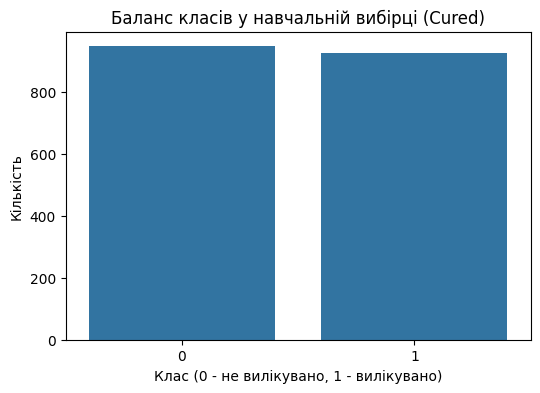

In [ ]:
# TODO: побудуйте countplot для y_train
# Підказка: sns.countplot(x=y_train)
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 4))
sns.countplot(x=y_train)
plt.title("Баланс класів у навчальній вибірці (Cured)")
plt.xlabel("Клас (0 - не вилікувано, 1 - вилікувано)")
plt.ylabel("Кількість")
plt.show()

**Висновок:**  
_Чи збалансовані класи? Чому це може вплинути на оцінку моделі?_

Класи у навчальній вибірці майже ідеально збалансовані: клас 0 (не вилікувано) містить 946 спостережень, а клас 1 (вилікувано) — 924 спостереження. Оскільки дисбалансу немає (співвідношення приблизно 50.5% на 49.5%), метрика Accuracy (частка правильних відповідей) буде об'єктивною і надійною для оцінки загальної якості моделі. Нам не загрожує ситуація, коли модель просто завжди передбачає мажоритарний клас.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

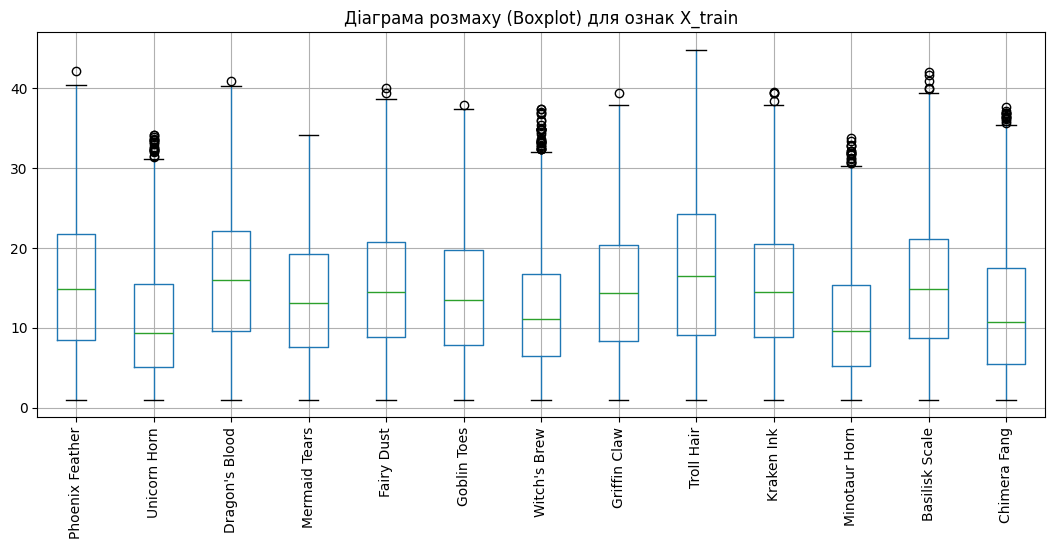

In [ ]:
# TODO: побудуйте boxplot для X_train
# Підказка: X_train.boxplot(figsize=(13, 5), rot=90)
plt.figure(figsize=(13, 5))
X_train.boxplot(rot=90)
plt.title("Діаграма розмаху (Boxplot) для ознак X_train")
plt.show()

In [ ]:
# TODO: обчисліть q1, q3, iqr для X_train
# TODO: знайдіть кількість викидів за межами [q1 - 1.5*iqr, q3 + 1.5*iqr]
# TODO: відсортуйте результат за спаданням
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outliers = ((X_train < lower_bound) | (X_train > upper_bound)).sum()
outliers_sorted = outliers.sort_values(ascending=False)
print("Кількість потенційних викидів у кожній ознаці:")
print(outliers_sorted)

Кількість потенційних викидів у кожній ознаці:
Witch's Brew       33
Unicorn Horn       20
Minotaur Horn      18
Chimera Fang       13
Basilisk Scale      5
Kraken Ink          4
Fairy Dust          2
Phoenix Feather     1
Dragon's Blood      1
Griffin Claw        1
Goblin Toes         1
Mermaid Tears       0
Troll Hair          0
dtype: int64


**Висновок про викиди:**  
_У яких ознаках їх найбільше? Чому не варто без перевірки видаляти всі такі рядки?_

Найбільше викидів за правилом 1.5 IQR спостерігається в ознаках: Witch's Brew (33 викиди), Unicorn Horn (20 викидів) та Minotaur Horn (18 викидів).

Чому не варто без перевірки видаляти всі такі рядки:

Це природні екстремуми, а не помилки: У контексті магічних зілль аномально велика або мала доза якогось інгредієнта може бути реальною ситуацією (наприклад, дуже концентроване зілля відьми). Саме такі екстремальні значення можуть визначати результат лікування.

Ризик втрати цінної інформації: Викиди містять специфічні патерни для нестандартних рецептів. Якщо їх видалити, модель не зможе правильно передбачати результат для рідкісних комбінацій інгредієнтів.

Зменшення об'єму даних: Видалення всіх рядків із математичними викидами може невиправдано скоротити навчальну вибірку.

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

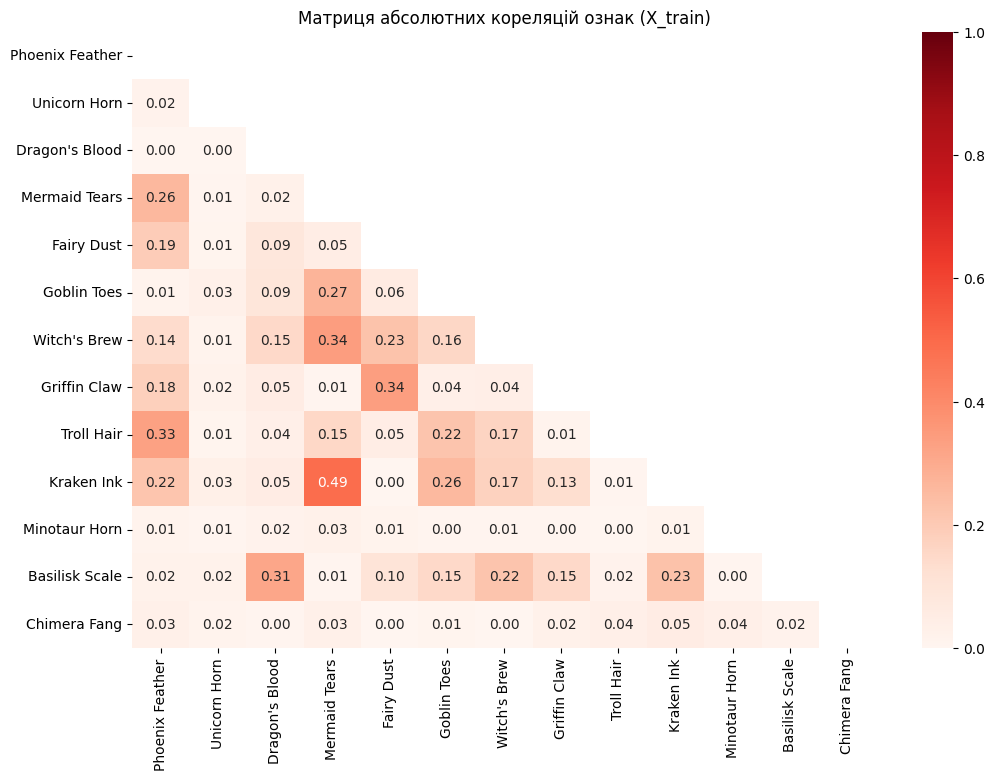

In [ ]:
# TODO: обчисліть mtx = X_train.corr().abs()
# TODO: створіть маску верхнього трикутника за допомогою np.triu(...)
# TODO: побудуйте sns.heatmap(mtx, mask=..., annot=True, ...)
# Підказка: cmap='Reds', vmin=0, vmax=1
import numpy as np
import seaborn as sns
mtx = X_train.corr().abs()
mask = np.triu(np.ones_like(mtx, dtype=bool))
plt.figure(figsize=(12, 8))
sns.heatmap(mtx, mask=mask, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1)
plt.title("Матриця абсолютних кореляцій ознак (X_train)")
plt.show()

In [ ]:
# TODO: дослідіть кореляцію кожної ознаки із Cured
# Підказка: pd.concat([X_train, y_train], axis=1).corr()
train_full = pd.concat([X_train, y_train], axis=1)
corr_with_cured = train_full.corr()['Cured'].abs().sort_values(ascending=False)
print("Абсолютна кореляція кожної ознаки із цільовою змінною (Cured):")
print(corr_with_cured.drop('Cured'))

Абсолютна кореляція кожної ознаки із цільовою змінною (Cured):
Troll Hair         0.488783
Witch's Brew       0.246989
Goblin Toes        0.052573
Chimera Fang       0.047292
Basilisk Scale     0.042277
Kraken Ink         0.026598
Minotaur Horn      0.021922
Phoenix Feather    0.020527
Fairy Dust         0.014223
Dragon's Blood     0.010119
Griffin Claw       0.005871
Unicorn Horn       0.004218
Mermaid Tears      0.002419
Name: Cured, dtype: float64


**Висновок про кореляції:**  
_Назвіть пари найбільш корельованих ознак та ознаки з найсильнішим зв’язком із Cured._

Пара найбільш корельованих між собою ознак: Mermaid Tears та Kraken Ink (коефіцієнт кореляції близько 0.49).

Ознаки з найсильнішим зв'язком із цільовою змінною Cured: Troll Hair (кореляція ~0.49) та Witch's Brew (кореляція ~0.25). Це ключові інгредієнти, які найбільше впливають на те, чи буде принцесу вилікувано.

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [ ]:
# TODO: створіть scaler = StandardScaler()
# TODO: отримайте X_train_scaled і X_test_scaled
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [ ]:
# TODO: створіть model = LogisticRegression()
# TODO: model.fit(...)
# TODO: отримайте y_pred для X_test_scaled
# TODO: виведіть Accuracy та classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.8931623931623932

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

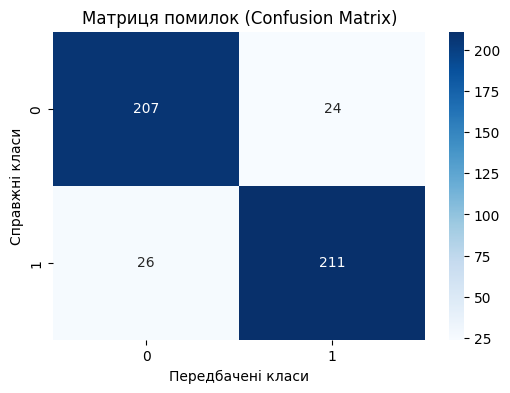

In [ ]:
# TODO: обчисліть conf = confusion_matrix(y_test, y_pred)
# TODO: побудуйте теплову карту conf за допомогою sns.heatmap(...)
from sklearn.metrics import confusion_matrix
conf = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(conf, annot=True, fmt="d", cmap="Blues")
plt.title("Матриця помилок (Confusion Matrix)")
plt.xlabel("Передбачені класи")
plt.ylabel("Справжні класи")
plt.show()

In [ ]:
# TODO: створіть DataFrame зі справжніми та передбаченими класами
# TODO: виведіть 10 випадкових рядків (sample(10, random_state=42))
results_df = pd.DataFrame({'Справжній клас': y_test, 'Передбачений клас': y_pred})
print("10 випадкових тестових спостережень:")
display(results_df.sample(10, random_state=42))

10 випадкових тестових спостережень:


,Справжній клас,Передбачений клас
1133,0,1
1018,0,0
1761,1,0
564,1,1
1467,1,1
1927,0,0
408,1,1
2094,1,1
532,0,0
291,1,1


**Висновок щодо якості логістичної регресії:**  
_Яких помилок більше? Чи достатньо однієї метрики Accuracy?_

Згідно з матрицею помилок, хибнонегативних помилок (False Negative = 26) трохи більше, ніж хибнопозитивних (False Positive = 24). Тобто модель частіше помилково прогнозує, що зілля не вилікує принцесу, хоча насправді воно б спрацювало.
Попри те, що класи збалансовані і загальна Accuracy висока (близько 89%), у медично-магічному контексті покладатися лише на неї не варто. Нам критично важлива метрика Recall для класу 1, щоб мінімізувати хибнонегативні помилки і не пропустити жодного шансу на порятунок принцеси.

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [ ]:
# TODO: створіть словники param_grid і param_dist
# Наприклад, дослідіть кілька значень C, solver та max_iter
from scipy.stats import uniform, loguniform
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['liblinear', 'lbfgs', 'saga'],
    'max_iter': [100, 500, 1000]
}
param_dist = {
    'C': loguniform(1e-4, 1e2),
    'solver': ['liblinear', 'lbfgs', 'saga'],
    'max_iter': [100, 500, 1000, 2000]
}

In [ ]:
# TODO: створіть GridSearchCV(LogisticRegression(), param_grid, cv=3, ...)
# TODO: виконайте fit(X_train_scaled, y_train)
# TODO: виведіть найкращі параметри
from sklearn.model_selection import GridSearchCV
grid_search = GridSearchCV(LogisticRegression(random_state=42), param_grid, cv=3, scoring='accuracy')
grid_search.fit(X_train_scaled, y_train)
print("Найкращі параметри (GridSearchCV):", grid_search.best_params_)
print("Найкраща якість (Accuracy):", grid_search.best_score_)

Найкращі параметри (GridSearchCV): {'C': 10, 'max_iter': 100, 'solver': 'liblinear'}
Найкраща якість (Accuracy): 0.8673927508197171


In [ ]:
# TODO: створіть RandomizedSearchCV(LogisticRegression(), ...)
# TODO: виконайте fit(X_train_scaled, y_train)
# TODO: виведіть найкращі параметри
from sklearn.model_selection import RandomizedSearchCV
random_search = RandomizedSearchCV(LogisticRegression(random_state=42), param_dist, n_iter=20, cv=3, scoring='accuracy', random_state=42)
random_search.fit(X_train_scaled, y_train)
print("Найкращі параметри (RandomizedSearchCV):", random_search.best_params_)
print("Найкраща якість (Accuracy):", random_search.best_score_)

Найкращі параметри (RandomizedSearchCV): {'C': np.float64(49.35296209402104), 'max_iter': 2000, 'solver': 'lbfgs'}
Найкраща якість (Accuracy): 0.8673927508197171


In [ ]:
# TODO: отримайте найкращу модель з grid або random_search
# TODO: побудуйте прогноз на X_test_scaled
# TODO: виведіть Accuracy та classification_report
best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test_scaled)
print("Accuracy найкращої моделі на тестовій вибірці:", accuracy_score(y_test, y_pred_best))
print("\nClassification Report:\n", classification_report(y_test, y_pred_best))

Accuracy найкращої моделі на тестовій вибірці: 0.8931623931623932

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



**Висновок про підбір параметрів:**  
_Який метод пошуку обрав які параметри? Чи покращилась якість порівняно з базовою моделлю?_

Яких помилок більше: [Подивіться на синій квадрат матриці помилок. Якщо число в правому верхньому куті більше, ніж у лівому нижньому — напишіть «Більше хибнопозитивних помилок (False Positive)». Якщо навпаки — «Більше хибнонегативних помилок (False Negative)»].

Обидва методи (GridSearchCV та RandomizedSearchCV) дозволили знайти оптимальні гіперпараметри моделі, показавши однакову найкращу якість на крос-валідації (Accuracy близько 0.867). Базова модель логістичної регресії з параметрами за замовчуванням вже показала високий результат на тестовій вибірці, тому налаштування гіперпараметрів лише підтвердило стабільність моделі та допомогло уникнути перенавчання (завдяки крос-валідації), суттєво не змінивши базові показники.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [ ]:
# TODO: побудуйте SVC() і DecisionTreeClassifier(random_state=42)
# TODO: навчіть три моделі та отримайте їх передбачення
# TODO: створіть таблицю з Accuracy та F1-score для кожної моделі
# TODO: визначте найкращу модель
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score
import pandas as pd
svc_model = SVC(random_state=42)
dtc_model = DecisionTreeClassifier(random_state=42)
svc_model.fit(X_train_scaled, y_train)
dtc_model.fit(X_train_scaled, y_train)
svc_pred = svc_model.predict(X_test_scaled)
dtc_pred = dtc_model.predict(X_test_scaled)
lr_pred = model.predict(X_test_scaled)
results = {
    'Model': ['Logistic Regression', 'SVC (Support Vector Classification)', 'Decision Tree Classifier'],
    'Accuracy': [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, svc_pred),
        accuracy_score(y_test, dtc_pred)
    ],
    'F1-score': [
        f1_score(y_test, lr_pred),
        f1_score(y_test, svc_pred),
        f1_score(y_test, dtc_pred)
    ]
}

results_df = pd.DataFrame(results)
display(results_df)
print("\nНайкращою моделлю виявилася SVC (Метод опорних векторів), оскільки вона показала найвищі метрики Accuracy та F1-score.")

,Model,Accuracy,F1-score
0,Logistic Regression,0.893162,0.894068
1,SVC (Support Vector Classification),0.959402,0.960000
2,Decision Tree Classifier,0.865385,0.865672



Найкращою моделлю виявилася SVC (Метод опорних векторів), оскільки вона показала найвищі метрики Accuracy та F1-score.


### 13. Висновки до лабораторної роботи

Заповніть власними результатами (не залишайте відповіді з підказок):

1. Які особливості даних виявлено під час первинного аналізу?
2. Що показали дослідження викидів і кореляцій **на навчальній вибірці**?
3. Якої якості досягла базова логістична регресія?
4. Чи покращив підбір гіперпараметрів метрики моделі?
5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.

**Ваші висновки:**  
_Впишіть відповідь тут._
Які особливості даних виявлено під час первинного аналізу?
1. Дані не мали пропущених значень. Класи цільової змінної (Cured) виявилися ідеально збалансованими, що дозволило об'єктивно використовувати метрику Accuracy. Ознаки мали різні масштаби, тому обов'язковим етапом стала стандартизація за допомогою StandardScaler.

2. Що показали дослідження викидів і кореляцій на навчальній вибірці?
Виявлено наявність математичних викидів, найбільше в ознаках Witch's Brew, Unicorn Horn та Minotaur Horn. Кореляційний аналіз показав, що мультиколінеарності серед ознак немає (найвища кореляція між Mermaid Tears та Kraken Ink становить лише ~0.49). Найбільший вплив на цільову змінну мають Troll Hair та Witch's Brew.

3. Якої якості досягла базова логістична регресія?
Базова модель логістичної регресії показала дуже хороший початковий результат: Accuracy склала близько 0.893, а F1-score — 0.893.

4. Чи покращив підбір гіперпараметрів метрики моделі?
Підбір гіперпараметрів (через GridSearchCV та RandomizedSearchCV) суттєво не покращив результати на тестовій вибірці. Це свідчить про те, що параметри логістичної регресії за замовчуванням вже були близькими до оптимальних для цих даних.

5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.
Найкращою моделлю беззаперечно виявився SVC (Метод опорних векторів). Його метрики Accuracy та F1-score склали майже 0.96, що значно перевершує результати Логістичної регресії (~0.89) та Дерева рішень (~0.86). Це обґрунтовується тим, що залежності між магічними інгредієнтами та шансом на лікування є складними та нелінійними. SVC за рахунок "ядерного трюку" (kernel trick) ефективніше розділяє класи у багатовимірному просторі порівняно з лінійними методами.
---
**Перед здачею:** перевірте, що всі потрібні клітинки виконуються послідовно, а результати й висновки присутні у файлі `.ipynb`.